# DrawData Tutorial and Example #

This builds on NeuralNine's introduction from: https://www.youtube.com/watch?v=CXVsGVSjNRw&t=3s
<br><br>
Drawdata is a libary that allows users to draw sample data sets in two dimensions.  Here we will show the power of that mixed with sklearn's decision boundary drawing and multiple ML algorithms to visualize model selection.

In [1]:
from drawdata import ScatterWidget


In [2]:
widget = ScatterWidget()


In [3]:
widget

ScatterWidget()

In [10]:
df = widget.data_as_pandas
df

,x,y,color,label
0,111.590725,132.973073,#1f77b4,a
1,104.492331,155.845936,#1f77b4,a
2,99.600135,169.142187,#1f77b4,a
3,104.829109,178.799904,#1f77b4,a
4,90.908787,184.536481,#1f77b4,a
...,...,...,...,...
552,341.394918,298.998273,#d62728,d
553,343.035189,321.243949,#d62728,d
554,359.614716,311.261613,#d62728,d
555,342.255463,310.036511,#d62728,d


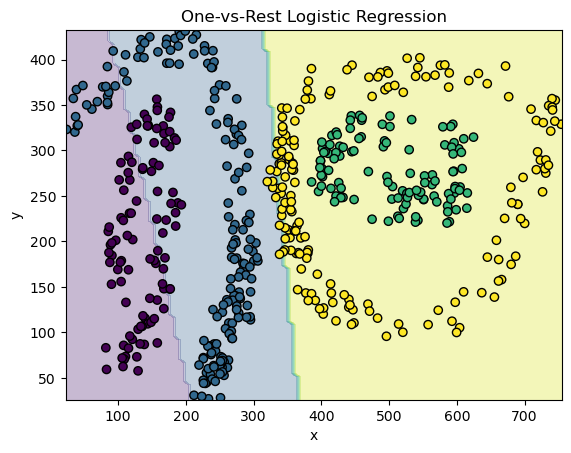

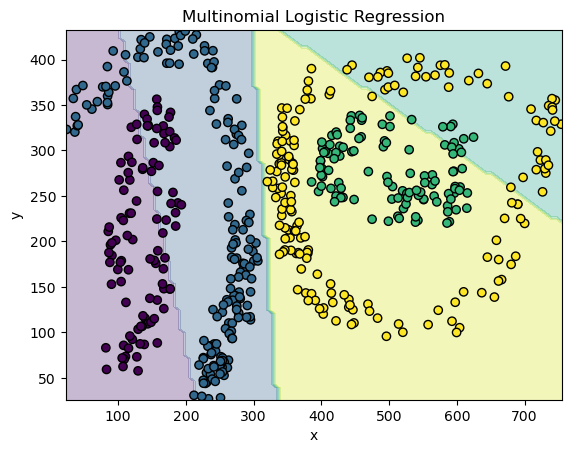

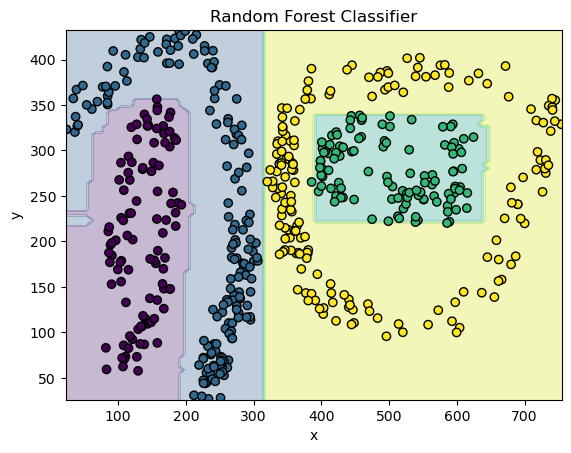

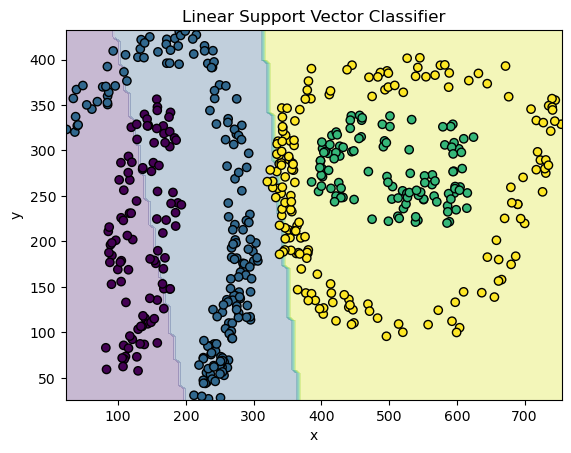

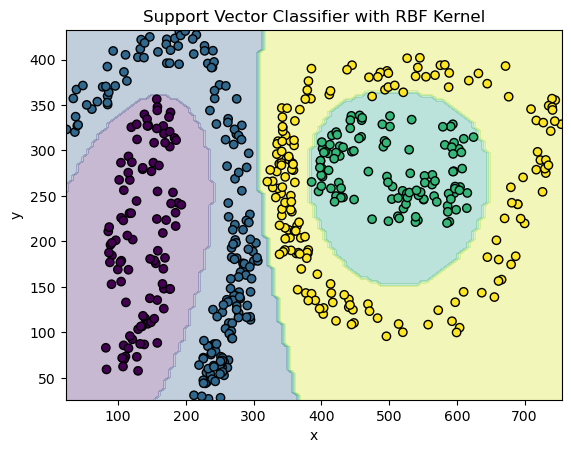

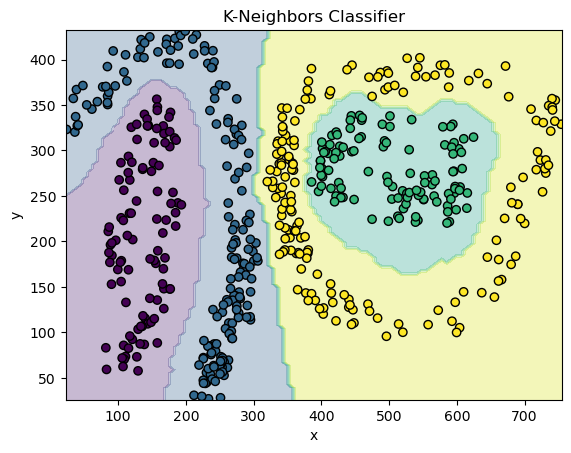

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.multiclass import OneVsRestClassifier

label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['label'])

X = df[['x', 'y']].values
y = df['label_encoded'].values

classifiers = {
    'One-vs-Rest Logistic Regression': OneVsRestClassifier(LogisticRegression()),
    'Multinomial Logistic Regression': LogisticRegression(solver='lbfgs'),
    'Random Forest Classifier': RandomForestClassifier(n_jobs=-1),
    'Linear Support Vector Classifier': LinearSVC(),
    'Support Vector Classifier with RBF Kernel': SVC(kernel='rbf'),
    'K-Neighbors Classifier': KNeighborsClassifier()
}

for name, clf in classifiers.items():
    clf.fit(X, y)
    disp = DecisionBoundaryDisplay.from_estimator(
        clf, X,
        response_method="predict",
        xlabel='x',
        ylabel='y',
        alpha=0.3
    )
    
    disp.ax_.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k')
    disp.ax_.set_title(name)
    plt.show()

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

import ipywidgets
from sklearn.inspection import DecisionBoundaryDisplay
from IPython.display import HTML

output = ipywidgets.Output()
widget3 = ScatterWidget()

classifier_selector = ipywidgets.RadioButtons(
    options=['Logistic Regression', 'Random Forest', 'SVC Poly', 'SVC RBF', 'K-Neighbors'],
    description='Classifier:',
)

@output.capture(clear_output=True)
def on_change(change):
    df = widget3.data_as_pandas
    if len(df) and (df['color'].nunique() > 1):
        X = df[['x', 'y']].values
        y = df['color']
        display(HTML("<br><br><br>"))
        fig = plt.figure(figsize=(12, 12))

        if classifier_selector.value == 'Logistic Regression':
            classifier = LogisticRegression().fit(X, y)
        elif classifier_selector.value == 'SVC Poly':
            classifier = SVC(kernel='poly').fit(X, y)
        elif classifier_selector.value == 'SVC RBF':
            classifier = SVC(kernel='rbf').fit(X, y)
        elif classifier_selector.value == 'K-Neighbors':
            classifier = KNeighborsClassifier().fit(X, y)
        else:
            classifier = RandomForestClassifier().fit(X, y)

        disp = DecisionBoundaryDisplay.from_estimator(
            classifier, 
            X,
            response_method="predict",
            xlabel="x", ylabel="y",
            alpha=0.5,
        )
        disp.ax_.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k")
        plt.title(f"{classifier.__class__.__name__}")
        plt.show()

widget3.observe(on_change, names=["data"])
classifier_selector.observe(on_change, names="value")
on_change(None)

ipywidgets.HBox([ipywidgets.VBox([widget3, classifier_selector]), output])